In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    print(mode(data, keepdims=True))
    return fig

Load data

In [3]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
regions_f = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.bed'

DHS_enrich_f = datadir + 'regions_25kb_CT20230202.DHS.counts.enrichment.hdf5'
epi_sums_f = datadir + 'regions_25kb_CT20230207.epilogos.statemeans.hdf5'

In [4]:
f = open(regions_f, 'r')
regions = []
for line in f.readlines():
    r = line.strip().split('\t')
    regions.append(r)
f.close()
regions = np.array(regions)

In [5]:
def print_coords(i):
    c = regions[i]
    return c[0] + ':' + c[1] + '-' + c[2]


def region_percentile(arr):
    # rank each region
    ranked_regions = rankdata(arr, axis=0)

    # find the number of regions with 0 values for each component
    comp_num_zero = len(arr) - np.count_nonzero(arr, axis=0)

    # adjusting/resetting ranks
    ranked_regions = ranked_regions - comp_num_zero
    ranked_regions = np.where(ranked_regions < 0, 0, ranked_regions)
    
    percentile = ranked_regions / np.max(ranked_regions, axis=0)

    return percentile

In [6]:
DHSalpha2paper_order = np.array([8, 3, 5, 1, 4, 15, 9, 6, 2, 12, 13, 11, 0, 10, 7, 14])
epialpha2paper_order = np.array([10, 12, 14, 13, 15, 16, 3, 4, 0, 1, 5, 17, 6, 11, 2, 8, 9, 7])

DHS_hdf5 = h5py.File(DHS_enrich_f, 'r')
DHS_enrich = DHS_hdf5['enrichment'][:][:, DHSalpha2paper_order]
DHS_counts = DHS_hdf5['counts'][:][:, DHSalpha2paper_order]
DHS_factors = np.char.decode(DHS_hdf5['factors'][:])[DHSalpha2paper_order]
DHS_hdf5.close()

epi_hdf5 = h5py.File(epi_sums_f, 'r')
epi_sum = epi_hdf5['state_means'][:][:, epialpha2paper_order]
epi_factors = np.char.decode(epi_hdf5['factors'][:])[epialpha2paper_order]
epi_hdf5.close()
epi_sum = np.where(epi_sum < 0, 0, epi_sum)

DHS_color = np.array(['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', 
                      '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3'])
epi_color = np.array(['#ff0000', '#ff4500', '#ff4500', '#ff4500', '#008000', '#006400', '#c2e105', '#c2e105',
                      '#ffc34d', '#ffc34d', '#ffff00', '#66cdaa', '#8a91d0', '#cd5c5c', '#bdb76b', '#808080', 
                      '#c0c0c0', '#ffffff'])

Percentiles and Joining

In [7]:
DHS_enrich_per = region_percentile(DHS_enrich)
DHS_count_per = region_percentile(DHS_counts)
DHS_per = (DHS_enrich_per + DHS_count_per) / 2
epi_per = region_percentile(epi_sum)

In [8]:
percents = np.hstack((DHS_per, epi_per))
factor_order = np.append(DHS_factors, epi_factors)
metric_order = np.append(np.array(['DHS signal'] * len(DHS_factors)),
                         np.array(['chromatin states'] * len(epi_factors)))
colors = np.append(DHS_color, epi_color)

In [9]:
# out_percents = np.hstack((regions, np.round(percents, 4)))
# out_header = np.append(
#     np.array(['chrm', 'start', 'end']),
#     joined_factor_order
# )

# out_full = np.vstack((out_header, out_percents))

# outfile = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20230131.DHS_epilogos_factor_percentiles.bed'
# np.savetxt(outfile, 
#            out_full, 
#            delimiter='\t', 
#            fmt='%s')

In [11]:
DHS_color_out = []
for i, j in zip(DHS_factors, DHS_color):
    print(i, j)
    DHS_color_out.append([i, j])
    
# outfile = '/home/ctrader/region_similarity/data/rank_based/DHS_component_colors_CT20230131.tsv'
# np.savetxt(outfile, 
#            np.array(DHS_color_out).T, 
#            delimiter='\t', 
#            fmt='%s')

Placental_trophoblast #FFE500
Lymphoid #FE8102
Myeloid_erythroid #FF0000
Cardiac #07AF00
Musculoskeletal #4C7D14
Vascular_endothelial #414613
Primitive_embryonic #05C1D9
Neural #0467FD
Digestive #009588
StromalA #BB2DD4
StromalB #7A00FF
Renal_cancer #4A6876
Cancer_epithelial #08245B
Pulmonarydevel #B9461D
Organdevel_renal #692108
Tissueinvariant #C3C3C3


Bad regions

In [16]:
for i in np.argsort(np.mean(percents, axis=1))[:10]:
    print(i, print_coords(i), np.round(np.mean(percents, axis=1)[i], 4))

30929 chr17:38218338-38247393 0.0207
62674 chr5:99194496-99219496 0.023
8183 chr10:42113752-42138752 0.0237
3860 chr1:148716700-148742818 0.0253
86862 chrX:117808837-117833837 0.0261
28430 chr16:32315479-32340479 0.0264
46731 chr22:16488510-16513510 0.0267
28462 chr16:33520733-33545733 0.0271
45700 chr21:13479479-13504479 0.0271
45704 chr21:13590079-13615079 0.0277


In [18]:
# roi = 62674

Top region for cardiac DHSs and Active Enhancer 2

In [12]:
DHS_factors

array(['Placental_trophoblast', 'Lymphoid', 'Myeloid_erythroid',
       'Cardiac', 'Musculoskeletal', 'Vascular_endothelial',
       'Primitive_embryonic', 'Neural', 'Digestive', 'StromalA',
       'StromalB', 'Renal_cancer', 'Cancer_epithelial', 'Pulmonarydevel',
       'Organdevel_renal', 'Tissueinvariant'], dtype='<U21')

In [13]:
epi_factors

array(['TssA', 'TssFlnk', 'TssFlnkU', 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1',
       'EnhG2', 'EnhA1', 'EnhA2', 'EnhWk', 'ZNF_Rpts', 'Het', 'TssBiv',
       'EnhBiv', 'ReprPC', 'ReprPCWk', 'Quies'], dtype='<U8')

In [108]:
target_DHS_ind = np.where(DHS_factors=='Neural')[0][0]
target_epi_ind = np.where(epi_factors=='EnhA2')[0][0]
print(target_DHS_ind, target_epi_ind)

7 9


In [109]:
ave_per = ((DHS_per[:, target_DHS_ind]) + 
           (epi_per[:, target_epi_ind])) / 2
for ind in np.argsort(-ave_per)[:20]:
    print(ind,
          print_coords(ind), '\t', 
          np.round(DHS_per[ind, target_DHS_ind], 4), 
          np.round(epi_per[ind, target_epi_ind], 4), 
          np.round(ave_per[ind], 4))

38441 chr2:66686468-66711468 	 0.9796 0.9943 0.9869
320 chr1:10663143-10688143 	 0.9761 0.9914 0.9837
32246 chr17:81050600-81075600 	 0.9698 0.9826 0.9762
29349 chr16:72834901-72859901 	 0.971 0.9697 0.9704
45786 chr21:16279479-16304479 	 0.9872 0.9337 0.9604
24374 chr14:90533256-90558256 	 0.9453 0.9738 0.9596
47073 chr22:27783612-27808612 	 0.963 0.9522 0.9576
85 chr1:3125636-3150636 	 0.9919 0.9195 0.9557
17881 chr12:92014224-92039224 	 0.9312 0.9729 0.952
52673 chr3:159837011-159862011 	 0.9193 0.9817 0.9505
61835 chr5:72280973-72305973 	 0.944 0.9556 0.9498
16545 chr12:49210617-49235617 	 0.9524 0.9464 0.9494
63990 chr5:141797433-141822835 	 0.9632 0.9339 0.9486
13841 chr11:94922635-94947635 	 0.966 0.9303 0.9482
4957 chr1:184609866-184634866 	 0.9085 0.9857 0.9471
37823 chr2:46981461-47006461 	 0.9021 0.9898 0.946
69428 chr6:138226663-138251663 	 0.9393 0.9525 0.9459
83056 chr9:129918521-129943521 	 0.9288 0.9626 0.9457
68565 chr6:110351597-110376597 	 0.927 0.9622 0.9446
66269 c

In [110]:
roi = 32830 # Cardiac and EnhA2 targeted
# roi = 61171 # Neural and TssBiv targeted
# roi = 36327 # Primitive_embryonic and ZNF_Rpts

Find regions based on what you want to see

In [111]:
dropdown_options = []
for name, i in zip(factor_order, range(len(factor_order))):
    dropdown_options.append((name, i))

In [112]:
factor_threshod = np.zeros(len(factor_order))

In [113]:
factor_dropdown = widgets.Dropdown(
    options=dropdown_options,
    description='Factor:',
)
factor_dropdown

Dropdown(description='Factor:', options=(('Placental_trophoblast', 0), ('Lymphoid', 1), ('Myeloid_erythroid', …

In [277]:
threshold_slider = widgets.BoundedFloatText(
    value=factor_threshod[factor_dropdown.value] * 100,
    min=0,
    max=100.0,
    step=0.1,
    description='Threshold %',
    disabled=False
)
threshold_slider

BoundedFloatText(value=0.0, description='Threshold %', step=0.1)

In [278]:
#setting threshold values
factor_threshod[factor_dropdown.value] = threshold_slider.value / 100
print(factor_threshod)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [279]:
filter_inds = np.where(
    np.count_nonzero(
        percents >= factor_threshod, axis=1
    ) == len(factor_order)
)[0]
print('%s regions available' %(len(filter_inds)))

88036 regions available


In [280]:
# for i in filter_inds:
#     print(i, print_coords(i))

Convolution

In [198]:
# # all regions at once
# t = time.time()
# conv_top = []
# sim_top = []
# regions_top = []
# for i in range(len(percents)):
#     if (i % 10000) == 0:
#         print(i)
#     i_percents = percents[i]
#     i_conv_all = percents * i_percents
#     i_sim_all = 1 - np.prod(1 - i_conv_all, axis=1)
#     i_top_regions = np.argsort(-i_sim_all)[:101]
#     i_top_regions = i_top_regions[i_top_regions != i][:100]
#     i_conv_top = i_conv_all[i_top_regions]
#     i_sim_top = i_sim_all[i_top_regions]
#     conv_top.append(i_conv_top)
#     sim_top.append(i_sim_top)
#     regions_top.append(i_top_regions)
# print(time.time()-t)

# conv_top = np.array(conv_top)
# sim_top = np.array(sim_top)
# regions_top = np.array(regions_top)

# out_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20230131.DHSsignalZ.epilogosmaxstateperbin.ranked.percentile.convolution.fusionsim.hdf5'
# out_f = h5py.File(out_path, 'w')
# out_f.create_dataset('convolution', data=conv_top)
# out_f.create_dataset('similarity', data=sim_top)
# out_f.create_dataset('regions', data=regions_top)
# out_f.create_dataset('factor_order', data=np.char.encode(joined_factor_order))
# out_f.create_dataset('metric_order', data=np.char.encode(joined_metric_order))
# out_f.create_dataset('ranks', data=joined_ranks)
# out_f.create_dataset('max_ranks', data=joined_max_ranks)
# out_f.create_dataset('percentiles', data=percents)
# out_f.close()

In [199]:
# print(regions_top.shape)
# print(sim_top.shape)
# print(conv_top.shape)

In [114]:
roi_percents = percents[roi]
print(roi_percents)

[0.61982076 0.         0.         0.9998008  0.30076034 0.
 0.48822528 0.         0.76356729 0.1718218  0.35696849 0.12019979
 0.11547941 0.43914005 0.34560946 0.         0.19615651 0.
 0.52353832 0.28704768 0.13129142 0.4096039  0.85613292 0.94663415
 0.94510159 0.99755981 0.20887301 0.         0.         0.
 0.62486899 0.54268654 0.65929677 0.        ]


In [115]:
t = time.time()
roi_conv_all = percents * roi_percents
print(time.time()-t)

0.045493125915527344


Fusion

In [116]:
t = time.time()
roi_sim_all = 1 - np.prod(1 - roi_conv_all, axis=1)
print(time.time()-t)

0.012538909912109375


In [117]:
top_regions = np.argsort(-roi_sim_all)[:101]
top_regions = np.append(roi, top_regions[top_regions!=roi][:100])

In [118]:
# similarity_out = []

In [119]:
# similarity_out.append(top_regions)

In [120]:
# similarity_out = np.array(similarity_out)
# similarity_out.shape

In [121]:
# outfile = '/home/ctrader/region_similarity/data/rank_based/convolution_fusion_similarity_hits_query_top100_CT20230131.tsv'
# np.savetxt(outfile, 
#            similarity_out, 
#            delimiter='\t', 
#            fmt='%s')

Score distribution

DescribeResult(nobs=88036, minmax=(0.0, 0.9999999999270714), mean=0.8679541475520242, variance=0.03185143491027652, skewness=-1.8731009014926294, kurtosis=3.9148849714843)
ModeResult(mode=array([0.]), count=array([425]))


Text(0.5, 1.0, 'Score Distribution for ROI 32830')

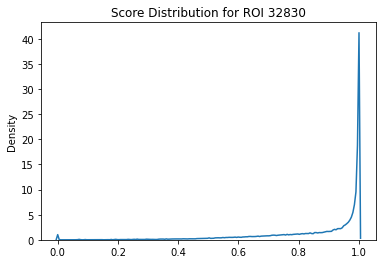

In [122]:
fig = kde_wrapper(roi_sim_all)
plt.title('Score Distribution for ROI ' + str(roi))

In [123]:
len(roi_sim_all)

88036

In [124]:
print(len(roi_sim_all[roi_sim_all>0]))
print(len(roi_sim_all[roi_sim_all>0.9]))
print(len(roi_sim_all[roi_sim_all>0.99]))
print(len(roi_sim_all[roi_sim_all>0.999]))
print(len(roi_sim_all[roi_sim_all>0.9999]))
print(len(roi_sim_all[roi_sim_all>0.99999]))
print(len(roi_sim_all[roi_sim_all>0.999999]))
print(len(roi_sim_all[roi_sim_all==1]))

87611
53525
28458
14888
7396
3234
1168
0


In [151]:
inds_over_thresh = np.where(percents[top_regions[0]] > 0.9)[0]
print('Query:',
      top_regions[0],
      len(inds_over_thresh),
      factor_order[inds_over_thresh],
      percents[top_regions[0]][inds_over_thresh],
      print_coords(top_regions[0])
     )
print()

for region in top_regions[1:11]:
    inds_over_thresh = np.where(roi_conv_all[region] > 0.9)[0]
    print(region,
          np.round(roi_sim_all[region], 9),
          len(inds_over_thresh),
          factor_order[inds_over_thresh],
          percents[region][inds_over_thresh],
          np.round(np.max(roi_conv_all[region]), 4),
          print_coords(region)
         )
    print()

Query: 32830 4 ['Cardiac' 'EnhG2' 'EnhA1' 'EnhA2'] [0.9998008  0.94663415 0.94510159 0.99755981] chr18:22183239-22208637

35737 1.0 4 ['Cardiac' 'EnhG2' 'EnhA1' 'EnhA2'] [0.99191383 0.98944675 0.99997789 0.99733039] 0.9949 chr19:38647160-38672160

49246 0.999999999 4 ['Cardiac' 'EnhG2' 'EnhA1' 'EnhA2'] [0.98969776 0.99536297 0.99973468 0.99192859] 0.9895 chr3:46924710-46949710

3805 0.999999999 4 ['Cardiac' 'EnhG2' 'EnhA1' 'EnhA2'] [0.98807926 0.99676207 0.99040439 0.99872776] 0.9963 chr1:145977486-146007428

64227 0.999999999 4 ['Cardiac' 'EnhG2' 'EnhA1' 'EnhA2'] [0.95420951 0.99264471 0.99159831 0.99981229] 0.9974 chr5:149404037-149429037

9556 0.999999999 3 ['Cardiac' 'EnhA1' 'EnhA2'] [0.9996763  0.97059409 0.99053121] 0.9995 chr10:86664043-86689043

5485 0.999999998 3 ['EnhG2' 'EnhA1' 'EnhA2'] [0.99444356 0.99628557 0.9968924 ] 0.9945 chr1:201488072-201513072

47345 0.999999998 4 ['Cardiac' 'EnhG2' 'EnhA1' 'EnhA2'] [0.96568826 0.99532299 0.9993146  0.99908232] 0.9966 chr22:36363755

Text(0, 0.5, 'Cardiac Percentile')

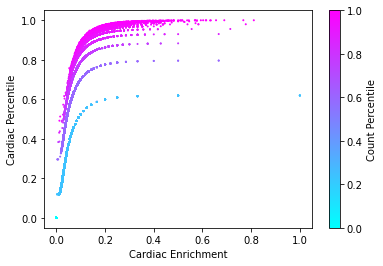

In [152]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(DHS_enrich[:, target_DHS_ind], 
            percents[:, target_DHS_ind], 
            s=1, 
            c=DHS_count_per[:, target_DHS_ind], 
            cmap='cool')

plt.colorbar(label='Count Percentile')
plt.xlabel(factor_order[target_DHS_ind] + ' Enrichment')
plt.ylabel(factor_order[target_DHS_ind] + ' Percentile')

Text(0, 0.5, 'Cardiac Enrichment Percentile')

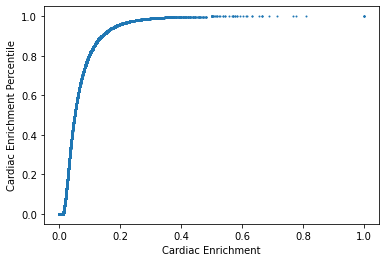

In [153]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(DHS_enrich[:, target_DHS_ind], 
            DHS_enrich_per[:, target_DHS_ind], 
            s=1)

plt.xlabel(factor_order[target_DHS_ind] + ' Enrichment')
plt.ylabel(factor_order[target_DHS_ind] + ' Enrichment Percentile')

In [154]:
DHS_enrich[78, target_DHS_ind]

0.05

In [155]:
DHS_enrich_per[78, target_DHS_ind]

0.5009959911356789

In [156]:
len(np.where(DHS_enrich[:, target_DHS_ind]<0.05)[0]) - len(np.where(DHS_enrich[:, target_DHS_ind]==0)[0])

19743

In [157]:
np.where(DHS_enrich[:, target_DHS_ind]>0.05)[0].shape

(19666,)

Text(0, 0.5, 'Cardiac Percentile')

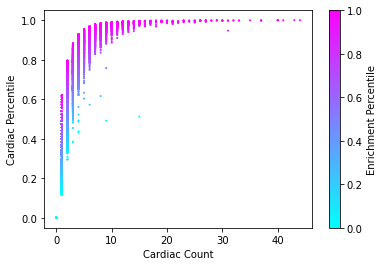

In [158]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(DHS_counts[:, target_DHS_ind], 
            percents[:, target_DHS_ind], 
            s=1, 
            c=DHS_enrich_per[:, target_DHS_ind], 
            cmap='cool')

# plt.xlim([0, 50])
plt.colorbar(label='Enrichment Percentile')
plt.xlabel(factor_order[target_DHS_ind] + ' Count')
plt.ylabel(factor_order[target_DHS_ind] + ' Percentile')

Text(0, 0.5, 'Cardiac Count Percentile')

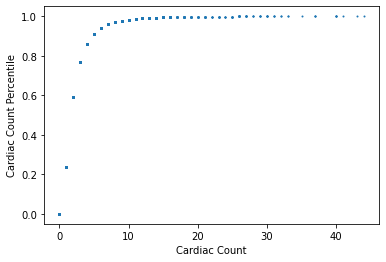

In [159]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(DHS_counts[:, target_DHS_ind], 
            DHS_count_per[:, target_DHS_ind], 
            s=1)

plt.xlabel(factor_order[target_DHS_ind] + ' Count')
plt.ylabel(factor_order[target_DHS_ind] + ' Count Percentile')

In [160]:
len(DHS_counts) - len(np.where(DHS_counts[:, target_DHS_ind]==0)[0])

40163

In [161]:
len(np.where(DHS_counts[:, target_DHS_ind]>3)[0])

6909

In [162]:
len(np.where(DHS_counts[:, target_DHS_ind]==3)[0])

4877

In [163]:
len(np.where(
    ((DHS_counts[:, target_DHS_ind]<3) & 
     (DHS_counts[:, target_DHS_ind]!=0))
)[0])

28377

In [164]:
(28377 + (4877 / 2)) / 40163

0.7672609117844783

Text(0, 0.5, 'Cardiac Enrichment')

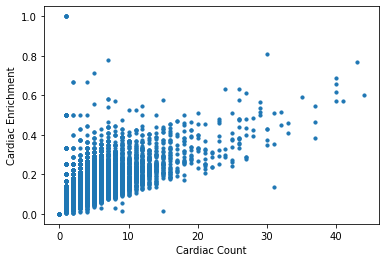

In [165]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(DHS_counts[:, target_DHS_ind], 
            DHS_enrich[:, target_DHS_ind], 
            s=10)

plt.xlabel(factor_order[target_DHS_ind] + ' Count')
plt.ylabel(factor_order[target_DHS_ind] + ' Enrichment')

DescribeResult(nobs=88036, minmax=(0.0, 1.0), mean=0.03150500960751854, variance=0.0028940699799164323, skewness=3.4067543968686116, kurtosis=21.5437208376258)
ModeResult(mode=array([0.]), count=array([47873]))


Text(0.5, 1.0, 'Cardiac Enrichment Distribution')

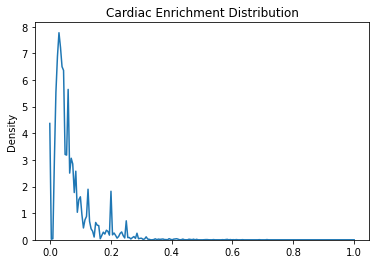

In [166]:
fig = kde_wrapper(DHS_enrich[:, target_DHS_ind])
plt.title(factor_order[target_DHS_ind] + ' Enrichment Distribution')

DescribeResult(nobs=88036, minmax=(0, 44), mean=1.081875596346949, variance=4.048592499591427, skewness=4.998834521728177, kurtosis=48.44859470860717)
ModeResult(mode=array([0]), count=array([47873]))


Text(0.5, 1.0, 'Cardiac Count Distribution')

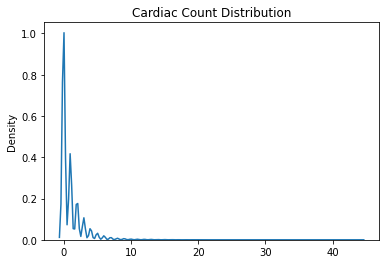

In [170]:
fig = kde_wrapper(DHS_counts[:, target_DHS_ind], bw=1)
plt.title(factor_order[target_DHS_ind] + ' Count Distribution')

Text(0.5, 1.0, 'Cardiac DHS Counts Per Region')

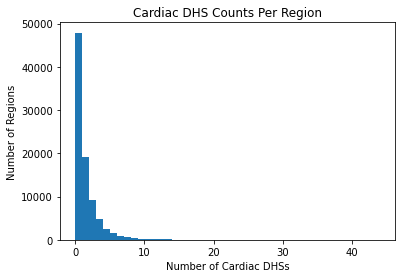

In [175]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(DHS_counts[:, target_DHS_ind], bins=np.arange(np.max(DHS_counts[:, target_DHS_ind])+1))
plt.ylabel('Number of Regions')
plt.xlabel('Number of Cardiac DHSs')
plt.title('Cardiac DHS Counts Per Region')

In [142]:
factor_order

array(['Placental_trophoblast', 'Lymphoid', 'Myeloid_erythroid',
       'Cardiac', 'Musculoskeletal', 'Vascular_endothelial',
       'Primitive_embryonic', 'Neural', 'Digestive', 'StromalA',
       'StromalB', 'Renal_cancer', 'Cancer_epithelial', 'Pulmonarydevel',
       'Organdevel_renal', 'Tissueinvariant', 'TssA', 'TssFlnk',
       'TssFlnkU', 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1', 'EnhG2', 'EnhA1',
       'EnhA2', 'EnhWk', 'ZNF_Rpts', 'Het', 'TssBiv', 'EnhBiv', 'ReprPC',
       'ReprPCWk', 'Quies'], dtype='<U21')

In [150]:
target_DHS_ind = np.where(factor_order=='Cardiac')[0][0]
print(factor_order[target_DHS_ind] + ':')
for region, i in zip(top_regions, range(len(top_regions))):
    print(i+1,
          np.round(percents[region, target_DHS_ind], 4),
          '\t',
          np.round(DHS_enrich[region, target_DHS_ind], 4),
          '->',
          np.round(DHS_enrich_per[region, target_DHS_ind], 4),
          '\t',
          DHS_counts[region, target_DHS_ind],
          '/',
          np.sum(DHS_counts[region]),
          '->',
          np.round(DHS_count_per[region, target_DHS_ind], 4))

Cardiac:
1 0.9998 	 0.6027 -> 0.9996 	 44 / 73 -> 1.0
2 0.9919 	 0.2747 -> 0.9851 	 25 / 91 -> 0.9987
3 0.9897 	 0.2527 -> 0.981 	 23 / 91 -> 0.9984
4 0.9881 	 0.2427 -> 0.9775 	 25 / 103 -> 0.9987
5 0.9542 	 0.1512 -> 0.9165 	 13 / 86 -> 0.9919
6 0.9997 	 0.5694 -> 0.9994 	 41 / 72 -> 1.0
7 0.8769 	 0.092 -> 0.7834 	 8 / 87 -> 0.9704
8 0.9657 	 0.1687 -> 0.9378 	 14 / 83 -> 0.9936
9 0.9819 	 0.2206 -> 0.969 	 15 / 68 -> 0.9948
10 0.9951 	 0.3469 -> 0.9938 	 17 / 49 -> 0.9965
11 0.9633 	 0.1837 -> 0.9487 	 9 / 49 -> 0.978
12 0.9501 	 0.1463 -> 0.9106 	 12 / 82 -> 0.9895
13 0.9988 	 0.4821 -> 0.9985 	 27 / 56 -> 0.9992
14 0.9174 	 0.1169 -> 0.8568 	 9 / 77 -> 0.978
15 0.3546 	 0.0227 -> 0.1172 	 2 / 88 -> 0.592
16 0.9663 	 0.1803 -> 0.9459 	 11 / 61 -> 0.9867
17 0.9684 	 0.1818 -> 0.9473 	 12 / 66 -> 0.9895
18 0.9407 	 0.1333 -> 0.8918 	 12 / 90 -> 0.9895
19 0.9579 	 0.1618 -> 0.9291 	 11 / 68 -> 0.9867
20 0.9744 	 0.2 -> 0.9593 	 12 / 60 -> 0.9895
21 0.8643 	 0.0897 -> 0.7693 	 7 / 78 

0
35
467
1752
6326
79456


Text(0.5, 1.0, 'Number of factors filtering')

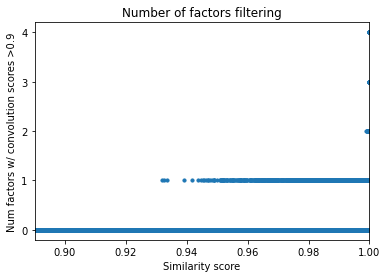

In [144]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(roi_sim_all, np.count_nonzero(roi_conv_all > 0.9, axis=1), s=10)

plt.xlim([0.89, 1])
plt.yticks([0, 1, 2, 3, 4])

plt.xlabel('Similarity score')
plt.ylabel('Num factors w/ convolution scores >0.9')
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==5))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==4))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==3))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==2))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==1))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==0))
plt.title('Number of factors filtering')

In [145]:
factor_order

array(['Placental_trophoblast', 'Lymphoid', 'Myeloid_erythroid',
       'Cardiac', 'Musculoskeletal', 'Vascular_endothelial',
       'Primitive_embryonic', 'Neural', 'Digestive', 'StromalA',
       'StromalB', 'Renal_cancer', 'Cancer_epithelial', 'Pulmonarydevel',
       'Organdevel_renal', 'Tissueinvariant', 'TssA', 'TssFlnk',
       'TssFlnkU', 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1', 'EnhG2', 'EnhA1',
       'EnhA2', 'EnhWk', 'ZNF_Rpts', 'Het', 'TssBiv', 'EnhBiv', 'ReprPC',
       'ReprPCWk', 'Quies'], dtype='<U21')

In [146]:
top_inds = top_regions[:100]

top_r = regions[top_inds]
top_factors_per_r = []
for ind in top_inds:
    factors_over_thresh = np.where(roi_conv_all[ind] > 0.9)[0]
    top_factors_per_r.append('/'.join(factor_order[factors_over_thresh]))
top_factors_per_r = np.array(top_factors_per_r)
top_r = np.hstack((top_r, top_factors_per_r.reshape(-1, 1)))

In [147]:
def roiurl_fusion(top_regions):
    today = date.today()
    query_region = '_'.join(top_regions[0, :3])
    roiurl_name = 'convolution_fusion_similarities_region_' + query_region + '_25kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roiurl_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path_epi = 'https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    link_path_index = 'https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    link_path_both = 'https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    print(link_path_epi)
    print(link_path_index)
    print(link_path_both)
    return # link_path_epi, link_path_index

In [148]:
roiurl_fusion(top_r)

https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fconvolution_fusion_similarities_region_chr18_22183239_22208637_25kb_CT20230207.bed
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fconvolution_fusion_similarities_region_chr18_22183239_22208637_25kb_CT20230207.bed
https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fconvolution_fusion_similarities_region_chr18_22183239_22208637_25kb_CT20230207.bed


Text(0.5, 1.0, 'Max convolution score filtering')

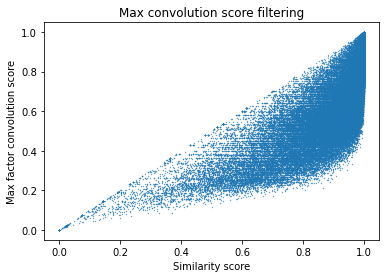

In [49]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(roi_sim_all, np.max(roi_conv_all, axis=1), s=0.1)

# plt.xlim([0.9, 1])
# plt.ylim([0.5, 1])
plt.xlabel('Similarity score')
plt.ylabel('Max factor convolution score')
plt.title('Max convolution score filtering')

**Narrate**

In [297]:
metriccolors = {
    'DHS signal': '\033[94m',
    'TF': '\033[92m',
    'chromatin states': '\033[91m',
    'STANDARD': '\033[0m',
    'BOLD': '\033[1m',
    'UNDERLINE': '\033[4m'
}

epi_conversion_dict = {
    'EnhA1': 'active enhancer 1',
    'EnhA2': 'active enhancer 2',
    'EnhBiv': 'bivalent enhancer',
    'EnhG1': 'genic enhancer 1',
    'EnhG2': 'genic enhancer 2',
    'EnhWk': 'weak enhancer',
    'Het': 'heterochromatin',
    'Quies': 'quiescent',
    'ReprPC': 'repressed polycomb',
    'ReprPCWk': 'weak repressed polycomb',
    'TssA': 'active TSS',
    'TssBiv': 'bivalent TSS',
    'TssFlnk': 'flanking TSS',
    'TssFlnkD': 'downstream flanking TSS',
    'TssFlnkU': 'upstream flanking TSS',
    'Tx': 'strong transcription',
    'TxWk': 'weak transcription',
    'ZNF_Rpts': 'ZNF genes + repeats'
}

DHS_conversion_dict = {
    'Cancer_epithelial': 'cancer/epithelial',
    'Cardiac': 'cardiac',
    'Digestive': 'digestive',
    'Lymphoid': 'lymphoid',
    'Musculoskeletal': 'musculoskeletal',
    'Myeloid_erythroid': 'myeloid/erythroid',
    'Neural': 'neural',
    'Organdevel_renal': 'organ development/renal',
    'Placental_trophoblast': 'placental/trophoblast',
    'Primitive_embryonic': 'primitive/embryonic',
    'Pulmonarydevel': 'pulmonary development',
    'Renal_cancer': 'renal/cancer',
    'StromalA': 'stromal A',
    'StromalB': 'stromal B',
    'Tissueinvariant': 'tissue invariant',
    'Vascular_endothelial': 'vascular/endothelial'
}

def narrate_sim(top_regions, roi_conv_top, joined_factor_order, joined_metric_order, thresh=0.9):
    query = top_regions[0]
    hits = top_regions[1:]
    roi_conv_hits = roi_conv_top[1:]
    sentences = []
    for region, roi_conv_hit in zip(hits, roi_conv_hits):
        sim_factors = np.where(roi_conv_hit > thresh)[0]
        if len(sim_factors) > 0:
            sentence = 'This region is highly similar to the query region in terms of '
            sim_factor_names = factor_order[sim_factors]
            sim_metric_names = metric_order[sim_factors]
            m_sections = []
            for m in np.unique(sim_metric_names):
                m_inds = np.where(sim_metric_names == m)[0]
                m_factors = sim_factor_names[m_inds]
                factors_joined = metriccolors[m]
                if len(m_factors) > 2:
                    factors_joined += ', '.join(m_factors[:-1])
                    factors_joined += ', and ' + m_factors[-1]
                elif len(m_factors) == 2:
                    factors_joined += ' and '.join(m_factors)
                else:
                    factors_joined += m_factors[0]
                    
                factors_joined += ' ' + m + metriccolors['STANDARD']
                m_sections.append(factors_joined)
            if len(m_sections) > 2:
                metrics_joined = ', '.join(m_sections[:-1])
                metrics_joined += ', and ' + m_sections[-1]
            if len(m_sections) == 2:
                metrics_joined = ' and '.join(m_sections)
            else:
                metrics_joined = m_sections[0]
                
            sentence += metrics_joined + '.'
        
        else:
            sentence = ''
        sentences.append(sentence)
    return sentences

sentences = narrate_sim(top_regions, roi_conv_all[top_regions], factor_order, metric_order)

for s in sentences:
    print(s)

This region is highly similar to the query region in terms of Neural DHS signal and TssBiv, EnhBiv, and ReprPC chromatin states.
This region is highly similar to the query region in terms of Neural DHS signal and TssBiv, EnhBiv, and ReprPC chromatin states.
This region is highly similar to the query region in terms of Neural DHS signal and TssBiv, EnhBiv, and ReprPC chromatin states.
This region is highly similar to the query region in terms of Neural DHS signal and TssBiv, EnhBiv, and ReprPC chromatin states.
This region is highly similar to the query region in terms of Neural DHS signal and TssBiv, EnhBiv, and ReprPC chromatin states.
This region is highly similar to the query region in terms of Neural DHS signal and TssBiv, EnhBiv, and ReprPC chromatin states.
This region is highly similar to the query region in terms of Neural DHS signal and TssBiv, EnhBiv, and ReprPC chromatin states.
This region is highly similar to the query region in terms of Neural DHS signal and TssBiv, EnhBi

**Tree plots**

Text(0.5, 0.91, 'Query Region Percentiles')

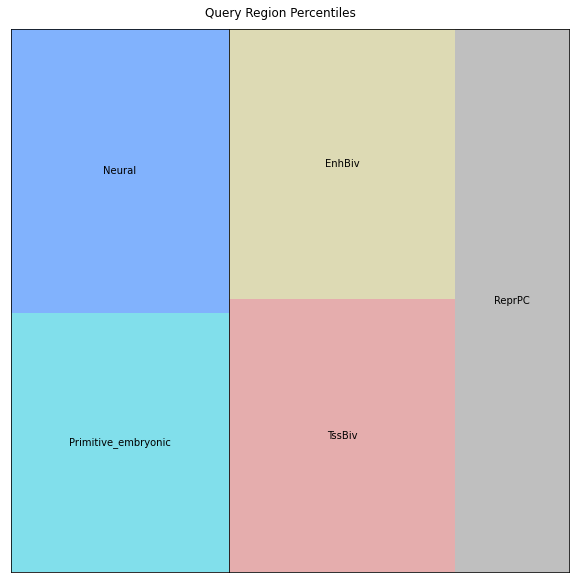

In [298]:
#query
factor_sums = percents[roi]
nonzero_inds = np.where(factor_sums>0.8)[0]
nonzero_factors = factor_sums[nonzero_inds]
nonzero_names = factor_order[nonzero_inds]
nonzero_color = colors[nonzero_inds]
nonzero_metrics = metric_order[nonzero_inds]

plot_ratios = []
for metric in np.unique(nonzero_metrics):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    plot_ratios.append(np.sum(nonzero_factors[metric_inds]))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,10), gridspec_kw={'width_ratios': plot_ratios})
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

for ax, metric in zip(axes, np.unique(nonzero_metrics)):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    squarify.plot(sizes=nonzero_factors[metric_inds], 
                  label=nonzero_names[metric_inds], 
                  alpha=0.5, 
                  color=nonzero_color[metric_inds],
                  ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
    
fig.suptitle('Query Region Percentiles', y=0.91)

Text(0.5, 0.91, 'Similar Region 1 Percentiles')

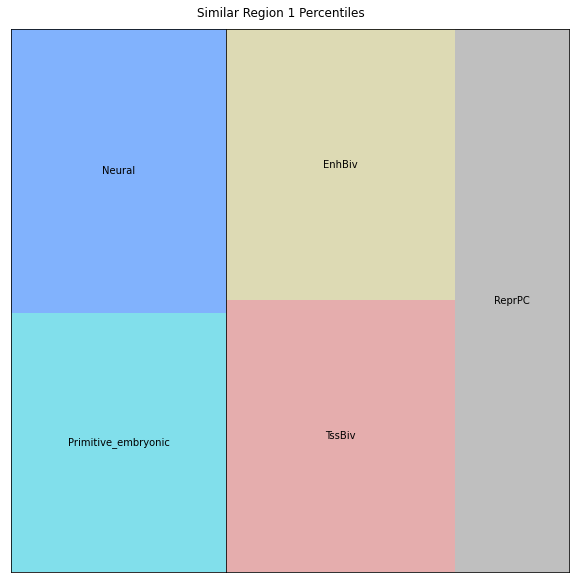

In [299]:
#hits

hit = 1
factor_sums = percents[top_regions[hit]]
nonzero_inds = np.where(factor_sums>0.85)[0]
nonzero_factors = factor_sums[nonzero_inds]
nonzero_names = factor_order[nonzero_inds]
nonzero_color = colors[nonzero_inds]
nonzero_metrics = metric_order[nonzero_inds]

plot_ratios = []
for metric in np.unique(nonzero_metrics):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    plot_ratios.append(np.sum(nonzero_factors[metric_inds]))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,10), gridspec_kw={'width_ratios': plot_ratios})
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

for ax, metric in zip(axes, np.unique(nonzero_metrics)):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    squarify.plot(sizes=nonzero_factors[metric_inds], 
                  label=nonzero_names[metric_inds], 
                  alpha=0.5, 
                  color=nonzero_color[metric_inds],
                  ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
    
fig.suptitle('Similar Region %s Percentiles' %(hit), y=0.91)

Text(0.5, 0.91, 'Similar Regions 1-10 Convolution Scores')

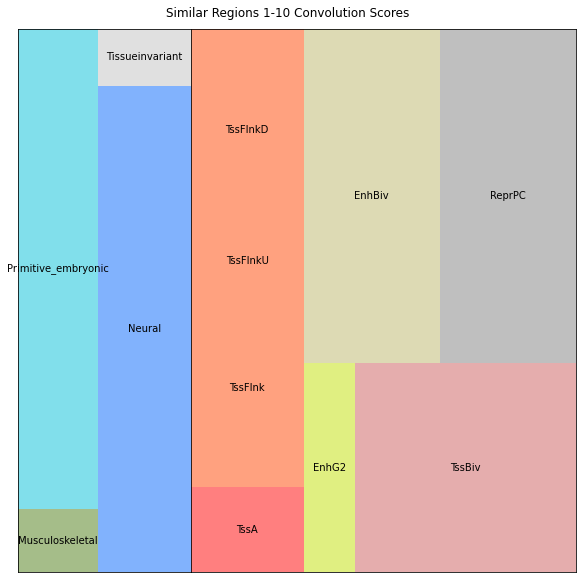

In [300]:
#top hits
start_hit = 1
end_hit = 10
factor_sums = np.sum(roi_conv_all[top_regions[start_hit:end_hit+1]], axis=0)
nonzero_inds = np.where(factor_sums>0.9)[0]
nonzero_factors = factor_sums[nonzero_inds]
nonzero_names = factor_order[nonzero_inds]
nonzero_color = colors[nonzero_inds]
nonzero_metrics = metric_order[nonzero_inds]


plot_ratios = []
for metric in np.unique(nonzero_metrics):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    plot_ratios.append(np.sum(nonzero_factors[metric_inds]))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,10), gridspec_kw={'width_ratios': plot_ratios})
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

for ax, metric in zip(axes, np.unique(nonzero_metrics)):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    squarify.plot(sizes=nonzero_factors[metric_inds], 
                  label=nonzero_names[metric_inds], 
                  alpha=0.5, 
                  color=nonzero_color[metric_inds],
                  ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle('Similar Regions %s-%s Convolution Scores' %(start_hit, end_hit), y=0.91)